# 01 · Data and image → embedding pipeline (Milestone 1)

This notebook covers Milestone 1:

1. Download COCO Captions val2017 and clean the 5,000 images and ~25,000 captions
2. Split by image into train / val / test (4,000 / 500 / 500)
3. Tokenize captions with the GPT-2 tokenizer
4. Encode every image with a frozen CLIP ViT-B/32 (pooled 512-d vector + 50×768 patch features)
5. Embed every caption with the CLIP text encoder and check it against its image
6. Five image : caption test runs through the whole pipeline

Set `LIMIT = 64` for a quick local check; use `None` for the full dataset.

In [1]:
# Run from the repo root (works whether Jupyter starts in notebooks/ or the root).
import warnings; warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm without ipywidgets
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import json, torch, transformers
print("torch", torch.__version__, "| transformers", transformers.__version__, "| CUDA", torch.cuda.is_available())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

torch 2.15.0+cpu | transformers 4.57.6 | CUDA False


In [2]:
LIMIT = None   # e.g. 64 for a quick test on a laptop
from src import data
# Download and clean only once. Re-running prepare() on a folder that holds only some of the images would drop
# the missing ones and rewrite captions.json / splits.json, so the cached result is reused when it exists.
if (data.PROC_DIR / "splits.json").exists() and (data.PROC_DIR / "prepare_report.json").exists():
    report = json.loads((data.PROC_DIR / "prepare_report.json").read_text(encoding="utf-8"))
    print("using the cleaned data in", data.PROC_DIR)
else:
    data.download(LIMIT)          # ~240 MB annotations + ~780 MB images (or LIMIT single images)
    report = data.prepare(LIMIT)  # clean captions, verify images, split

using the cleaned data in data\processed


## Cleaning report

What the cleaning step removed or converted. Non-RGB images are kept and converted to RGB before CLIP.

In [3]:
import pandas as pd
pd.Series(report, name='count').to_frame()

,count
raw_images,5000
raw_captions,25014
missing_files,0
corrupt_images,0
non_rgb_images,10
empty_captions,0
duplicate_captions,14
kept_images,5000
kept_captions,25000
val_images,500


## GPT-2 tokenization

Captions get a leading space (GPT-2 merges it into the first word) and end with `<|endoftext|>`. The model input is `[bos] + caption + [eos]`; GPT-2 uses `<|endoftext|>` for both.

In [4]:
from transformers import GPT2TokenizerFast
tok = GPT2TokenizerFast.from_pretrained('gpt2')
caps, splits = data.load_captions(), data.load_splits()
example = next(iter(caps.values()))['captions'][0]
ids = tok.encode(' ' + example)
print(example)
print(ids)
print([tok.decode([i]) for i in ids])
{k: len(v) for k, v in splits.items()}

Different people are doing skateboard tricks and riding.
[20615, 661, 389, 1804, 22647, 3526, 15910, 290, 10311, 13]
[' Different', ' people', ' are', ' doing', ' skate', 'board', ' tricks', ' and', ' riding', '.']


{'val': 500, 'test': 500, 'train': 4000}

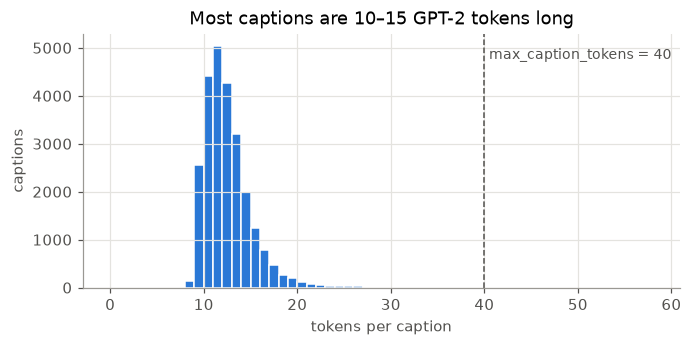

{'n_captions': 25000,
 'mean': 12.09,
 'p50': 12,
 'p95': 17,
 'p99': 21,
 'max': 57,
 'over_40': 7}

In [5]:
import matplotlib.pyplot as plt
# Fixed categorical order (validated reference palette); recessive grid, no top/right spines.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=SERIES), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.8, "axes.edgecolor": "#9a9893", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
                     "figure.dpi": 110, "font.size": 10})

lengths = [len(tok.encode(' ' + c)) for r in caps.values() for c in r['captions']]
stats = data.caption_length_stats(caps, tok, max_tokens=40)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(lengths, bins=range(0, max(lengths) + 2), color=SERIES[0], edgecolor='white', linewidth=1)
ax.axvline(40, color='#52514e', linestyle='--', linewidth=1)
ax.text(40.5, ax.get_ylim()[1] * 0.9, 'max_caption_tokens = 40', color='#52514e', fontsize=9)
ax.set(title='Most captions are 10–15 GPT-2 tokens long', xlabel='tokens per caption', ylabel='captions')
plt.show(); stats

## CLIP image embeddings

Computed once with `python -m src.data embed` and cached in `data/processed/clip_clip-vit-base-patch32.pt`
(pooled 512-d vector + 50 × 768 patch features per image, ~0.4 GB in fp16). Training never reads images again,
which is what makes each experiment fast. A pooled-only copy (`..._pooled.pt`, 5 MB) is enough for this notebook
and for the prefix model, so a laptop without the full file uses that one.

In [6]:
CLIP = 'openai/clip-vit-base-patch32'
full = data.embedding_path(CLIP)                          # pooled + patch features
pooled_only = full.with_name(full.stem + '_pooled.pt')    # pooled vectors only
path = full if full.exists() else pooled_only if pooled_only.exists() else None
if path is None:                                          # nothing cached yet: encode every image (GPU recommended)
    data.embed(CLIP, device=DEVICE)
    path = full
emb = torch.load(path, map_location='cpu')
emb['index'] = {iid: k for k, iid in enumerate(emb['image_ids'])}
assert set(emb['image_ids']) == set(caps), 'embeddings were computed for a different set of images'
patch = emb.get('patch')
print(path.name, '| pooled', tuple(emb['pooled'].shape),
      '| patch', tuple(patch.shape) if patch is not None else '(not in this file; 50 x 768 per image in the full file)')

clip_clip-vit-base-patch32_pooled.pt | pooled (5000, 512) | patch (not in this file; 50 x 768 per image in the full file)


Sanity check: an image's nearest neighbour in CLIP space should show similar content.

In [7]:
import torch.nn.functional as F
P = F.normalize(emb['pooled'].float(), dim=-1)
sims = P @ P.T
sims.fill_diagonal_(-1)
print('mean cosine similarity between different images:', round(float(sims[sims > -1].mean()), 3))
q = emb['image_ids'][0]; nn = emb['image_ids'][int(sims[0].argmax())]
print('query :', caps[q]['captions'][0]); print('neighbour:', caps[nn]['captions'][0])

mean cosine similarity between different images: 0.468
query : A woman stands in the dining area at the table.
neighbour: A person setting in a chair in a living room with a fireplace and windows.


## CLIP text embeddings of the captions

Every cleaned caption is also embedded with the CLIP text encoder (a 12-layer Transformer) into a 512-d vector,
cached in `data/processed/clip_text_clip-vit-base-patch32.pt`. Comparing each caption with its own image gives a
data check: `rank` is the position of the caption's own image among all 5,000 images (1 = best match).
Captions whose own image is not in their top 100 are flagged for review in `results/caption_check.json`;
none are removed, so the training data stay the same.

In [8]:
import json
if not data.text_embedding_path(CLIP).exists():
    data.embed_text(CLIP, device=DEVICE)
txt = torch.load(data.text_embedding_path(CLIP), map_location='cpu')
print('caption embeddings:', tuple(txt['text'].shape))
check = json.loads(Path('results/caption_check.json').read_text(encoding='utf-8'))
display(pd.Series({k: v for k, v in check.items() if k not in ('flagged',)}, name='value').to_frame())
pd.DataFrame(check['flagged'][:10])   # worst matches: several are crowd-worker notes, not captions

caption embeddings: (25000, 512)


,value
clip_model,openai/clip-vit-base-patch32
n_captions,25000
n_images,5000
flag_rule,own image not in top 100
own_sim,"{'mean': 0.305, 'p05': 0.249, 'p50': 0.305, 'p..."
mean_other_sim,0.151
own_higher_than_mean_other,0.9991
own_image_rank,"{'top1': 0.3052, 'top10': 0.6635, 'median': 4}"
captions_with_rank_over,"{'100': 1043, '500': 110, '1000': 58, '2000': 28}"
flagged_captions,1043


,image_id,caption,rank,own_sim
0,35279,Unable to see this image in this particular hit.,4804,0.182
1,521956,I am unable to see an image above.,4741,0.175
2,133645,There is no image to be reviewed on this hit.,4492,0.153
3,344029,No image again there are a lot of these lately.,4487,0.159
4,486104,A photo of a person being taken in this picture.,4485,0.185
5,38118,I am unable to see the image above.,4432,0.183
6,229747,A photo of an outside with various things in t...,4241,0.198
7,52017,I am unable to see an image above.,4188,0.184
8,5600,There are some appealing support ready to expend.,4006,0.190
9,197022,There is an image of man doing things on the t...,3748,0.186


## Five image : caption test runs

Five test images through the whole pipeline (the five in Table 3 of the Milestone 1 proposal), each with one
reference caption:

- **GPT-2 tokens** of the caption, the target sequence the decoder will learn to write
- **CLIP similarity own / others**: cosine between the image embedding and the CLIP text embedding of its own
  caption, against the mean over the other four captions. Own should be higher.
- **retrieval**: the caption of the most similar *training* image in CLIP space (no training needed)
- **untrained**: GPT-2 conditioned on a randomly initialised prefix. It is not meant to be good; it proves
  image → CLIP → mapping → GPT-2 → text runs end to end before training starts in Milestone 2.

,image,reference caption,GPT-2 tokens,n tokens,CLIP own,CLIP others
0,175251,A toddler in the bathroom brushing his teeth.,·A ·toddler ·in ·the ·bathroom ·brushing ·his ·teeth . <|endoftext|>,10,0.34,0.12
1,307598,"A yellow and green train, at stop lights.","·A ·yellow ·and ·green ·train , ·at ·stop ·lights . <|endoftext|>",11,0.30,0.14
2,108244,A black cat with a hat on the ground.,·A ·black ·cat ·with ·a ·hat ·on ·the ·ground . <|endoftext|>,11,0.27,0.13
3,263594,A bird walking past a white car in a lot.,·A ·bird ·walking ·past ·a ·white ·car ·in ·a ·lot . <|endoftext|>,12,0.25,0.18
4,440171,A man is sitting on the back of an elephant.,·A ·man ·is ·sitting ·on ·the ·back ·of ·an ·elephant . <|endoftext|>,12,0.28,0.13


every image is most similar to its own caption: True
175251
  REF      : A toddler in the bathroom brushing his teeth.
  retrieval: A infant holding a baby toothbrush in his hand looking at it.
  untrained: The U.S. is the world's most popular and most popular country for the purpose of the U
307598
  REF      : A yellow and green train, at stop lights.
  retrieval: A large long train on a steel track.
  untrained: The U.S. is the world's largest producer of food, with a total of more than $
108244
  REF      : A black cat with a hat on the ground.
  retrieval: A black and white cat wearing a little purple hat.
  untrained: The first time I saw the new "The Last of Us" trailer, I was a little bit surprised
263594
  REF      : A bird walking past a white car in a lot.
  retrieval: A cardinal perches on the side window mirror of a parked sedan.
  untrained: The first of the new "The New York Times" series, "The New York Times: The New
440171
  REF      : A man is sitting on the back of a

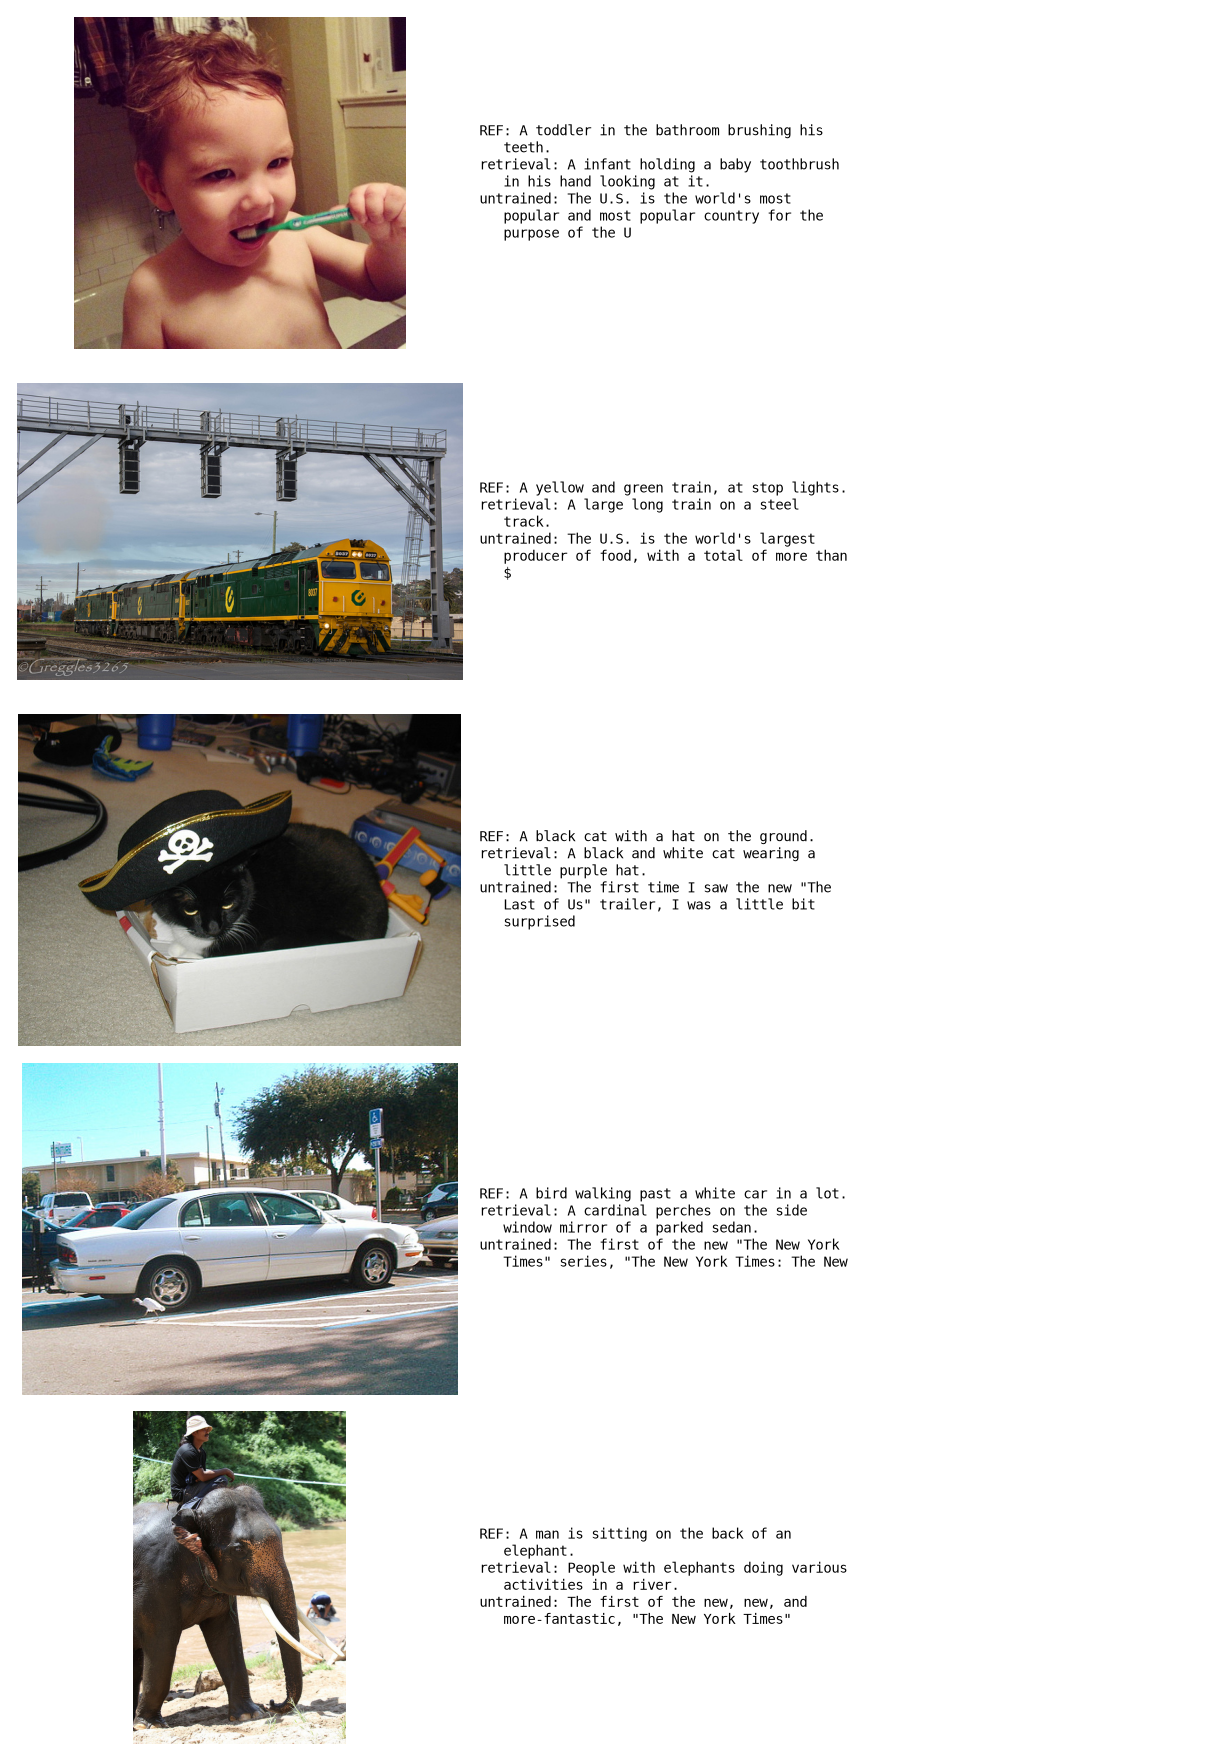

In [9]:
from IPython.display import Image as Show
import torch.nn.functional as F
from src.evaluate import retrieval_captions, save_gallery
from src.model import ClipCaptionModel, load_tokenizer
from src.decode import greedy

ids5 = ['175251', '307598', '108244', '263594', '440171']   # test images, as in the proposal
assert all(i in splits['test'] for i in ids5)
refs = [caps[i]['captions'][0] for i in ids5]

# CLIP similarity: image i against the text embedding of caption j
row = {tuple(k): n for n, k in enumerate(txt['keys'])}
I = F.normalize(emb['pooled'][[emb['index'][i] for i in ids5]].float(), dim=-1)
T = F.normalize(txt['text'][[row[(i, 0)] for i in ids5]].float(), dim=-1)
S = I @ T.T
own, others = S.diag(), (S.sum(1) - S.diag()) / (len(ids5) - 1)

retr = retrieval_captions(ids5, emb, caps, splits)
torch.manual_seed(0)
untrained = ClipCaptionModel('gpt2', 'prefix', 'prefix', feat_dim=512).eval()
feats = emb['pooled'][[emb['index'][i] for i in ids5]].float()
raw = dict(zip(ids5, greedy(untrained, feats, load_tokenizer(), max_len=20)))

pd.set_option('display.max_colwidth', None)
# tokens exactly as CaptionDataset feeds them to GPT-2: leading space, then <|endoftext|>
display(pd.DataFrame({
    'image': ids5, 'reference caption': refs,
    'GPT-2 tokens': [' '.join(tok.convert_ids_to_tokens(tok.encode(' ' + c))).replace('\u0120', '·') + ' <|endoftext|>'
                     for c in refs],
    'n tokens': [len(tok.encode(' ' + c)) + 1 for c in refs],
    'CLIP own': own.numpy().round(2), 'CLIP others': others.numpy().round(2)}))
print('every image is most similar to its own caption:', bool((S.argmax(1) == torch.arange(len(ids5))).all()))
for i in ids5:
    print(f'{i}\n  REF      : {caps[i]["captions"][0]}\n  retrieval: {retr[i]}\n  untrained: {raw[i]}')
Show(str(save_gallery(ids5, {'retrieval': retr, 'untrained': raw}, caps, Path('results/m1_test_runs.png'))))